# Looping Over Dimensions, and the Complex Inner Product

Three Calc-2-plus-programming exercises, each run in a **loop**:

| § | loop over | math | programming lesson |
|---|---|---|---|
| 1 | dimension $d$ = 0.5, 1, 1.5, …, 10 | ball volume $V_d = \pi^{d/2}/\Gamma(d/2+1)$ from a Gaussian integral | Monte Carlo: throw random points, count hits |
| 2 | dimension $d$ | Gauss's law for Thomson's uniform "pudding" in $d$ dimensions | symbolic code that works for *any* $d$ |
| 3 | vector length $n$ | complex inner product $\langle u,v\rangle = \sum \bar u_i v_i$ | `np.dot` vs. `np.vdot`, MATLAB `'` vs. `.'` |

Module: [`dgs/dimensions_inner_product.py`](../dgs/dimensions_inner_product.py) · MATLAB:
[`learn/matlab/dimensions_inner_product.m`](../learn/matlab/dimensions_inner_product.m)

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.dimensions_inner_product import (
    d_sym, ball_volume_symbolic, ball_volume, ball_volume_mc, peak_dimension,
    thomson_field_d, inner, norm, cauchy_schwarz_holds, fourier_inner_symbolic,
)

# 1. The volume of a ball in $d$ dimensions

**The Calc 2 trick.** Compute $\int_{\mathbb R^d} e^{-|x|^2}\,d^dx$ two ways.

- *As a product* of $d$ one-dimensional Gaussian integrals: $\left(\int e^{-x^2}dx\right)^d = \pi^{d/2}$.
- *In spherical shells:* the area of a shell of radius $r$ is $S_{d-1}r^{d-1}$, so the integral is $S_{d-1}\int_0^\infty r^{d-1}e^{-r^2}dr$, an improper integral that equals $\tfrac12\Gamma(d/2)$.

Set the two equal and solve for the unknown area $S_{d-1}$. SymPy does both steps:

In [2]:
S, V = ball_volume_symbolic()
display(Math(r"S_{d-1} = " + sp.latex(S) + r",\qquad V_d = \frac{S_{d-1}}{d} = " + sp.latex(V)))
for d in (1, 2, 3):
    display(Math(rf"d = {d}:\quad S = " + sp.latex(sp.simplify(S.subs(d_sym, d))) + r",\quad V = " + sp.latex(sp.simplify(V.subs(d_sym, d)))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The familiar formulas come out: length 2, area $\pi$, volume $\tfrac43\pi$. Because
$\Gamma$ is defined for *every* positive number, the formula also gives a value at
$d = 2.5$. Now loop over dimensions, and check the integer ones by **Monte Carlo**:
throw random points into the cube $[-1,1]^d$ and count the fraction that land inside
the ball.

    d    formula  Monte Carlo
  0.5     1.4688            —
  1.0     2.0000       2.0000
  1.5     2.5675            —
  2.0     3.1416       3.1405
  2.5     3.6915            —
  3.0     4.1888       4.1784
  4.0     4.9348       4.9180
  5.0     5.2638       5.2226
  6.0     5.1677       5.1270
  8.0     4.0587       3.9974
 10.0     2.5502       2.4550


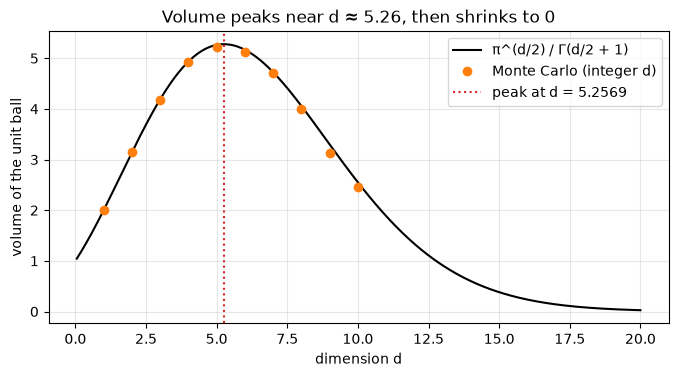

In [3]:
print(f"{'d':>5s} {'formula':>10s} {'Monte Carlo':>12s}")
for d in (0.5, 1, 1.5, 2, 2.5, 3, 4, 5, 6, 8, 10):
    mc = f"{ball_volume_mc(d):12.4f}" if float(d).is_integer() else f"{'—':>12s}"
    print(f"{d:5.1f} {float(ball_volume(d)):10.4f} {mc}")
dd = np.linspace(0.05, 20, 600); dpk = peak_dimension()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(dd, ball_volume(dd), "k", label="π^(d/2) / Γ(d/2 + 1)")
ax.plot(range(1, 11), [ball_volume_mc(d) for d in range(1, 11)], "o", color="C1", label="Monte Carlo (integer d)")
ax.axvline(dpk, color="C3", ls=":", label=f"peak at d = {dpk:.4f}")
ax.set(xlabel="dimension d", ylabel="volume of the unit ball", title="Volume peaks near d ≈ 5.26, then shrinks to 0")
ax.legend(); ax.grid(alpha=0.3); plt.show()

**Surprise:** the unit ball's volume peaks at $d \approx 5.26$, then goes to zero. In
high dimensions almost all of a cube's volume sits in its corners, outside the ball.
That's why the Monte Carlo hit rate collapses for $d = 10$ (the error grows), and why
"the curse of dimensionality" troubles machine learning.

# 2. Thomson's plum pudding in $d$ dimensions (Gauss's law)

Back to the quiz question. Thomson's atom is a **uniform ball of positive charge**.
Gauss's law in $d$ dimensions says flux through a sphere = enclosed charge / $\varepsilon$:

$$E(r)\,S_{d-1}r^{d-1} = \frac{Q_\text{enc}}{\varepsilon},\qquad Q_\text{enc} = Q\left(\frac rR\right)^d \ (r < R)$$

In [4]:
ins, out, (Q, eps, R, r) = thomson_field_d()
display(Math(r"E_\text{inside} = " + sp.latex(ins) + r",\qquad E_\text{outside} = " + sp.latex(out)))
for d in (1, 2, 3, sp.Rational(5, 2)):
    i_d, o_d, _ = thomson_field_d(d)
    display(Math(rf"d = {sp.latex(d)}:\quad E_\text{{in}} = " + sp.latex(i_d) + r",\quad E_\text{out} = " + sp.latex(o_d)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In **every** dimension the field inside a uniform ball grows *linearly* with $r$. It
never gets strong enough to turn an alpha around, which is the heart of why the plum
pudding failed (see `thomson_vs_rutherford.ipynb`). Outside, it falls as $r^{1-d}$.
That's Coulomb's $1/r^2$ in three dimensions: the inverse-square law is really a
statement about living in 3D.

# 3. The complex inner product

For complex vectors, length must come from $|z|^2 = \bar z z$, not $z^2$. So the inner
product **conjugates the first vector**:

$$\langle u, v\rangle = \sum_i \bar u_i\,v_i,\qquad \langle u, u\rangle = \sum_i |u_i|^2 \ge 0$$

Written as a plain loop:

```python
total = 0j
for a, b in zip(u, v):
    total += a.conjugate() * b
```

In [5]:
u, v = [1 + 2j, 3 - 1j], [2j, 1]
print(f"loop inner(u, v) = {inner(u, v)}")
print(f"np.vdot(u, v)    = {np.vdot(u, v)}     (conjugates first argument — correct)")
print(f"np.dot(u, v)     = {np.dot(u, v)}     (no conjugate — NOT an inner product)")
print(f"⟨u, u⟩ = {inner(u, u)}  → |u| = {norm(u):.4f}")
rng = np.random.default_rng(1); ok = True
for n in range(1, 11):                          # loop over vector lengths
    a = rng.normal(size=n) + 1j*rng.normal(size=n); b = rng.normal(size=n) + 1j*rng.normal(size=n)
    ok &= cauchy_schwarz_holds(a, b) and np.isclose(inner(a, b), np.conj(inner(b, a)))
print(f"Cauchy–Schwarz and conjugate symmetry hold for n = 1…10: {ok}")

loop inner(u, v) = (7+3j)
np.vdot(u, v)    = (7+3j)     (conjugates first argument — correct)
np.dot(u, v)     = (-1+1j)     (no conjugate — NOT an inner product)
⟨u, u⟩ = (15+0j)  → |u| = 3.8730
Cauchy–Schwarz and conjugate symmetry hold for n = 1…10: True


**The continuous version** (Calc 2): for functions,
$\langle f, g\rangle = \int \bar f\,g\,dx$. The Fourier modes $e^{ikx}$ are orthogonal on
$[0, 2\pi]$. That's why Fourier series work, and why quantum states (complex wave
functions) use exactly this inner product.

In [6]:
ks = range(-2, 3)
M = sp.Matrix([[fourier_inner_symbolic(k, m) for m in ks] for k in ks])
display(Math(r"\left[\langle e^{ikx}, e^{imx}\rangle\right]_{k,m=-2}^{2} = " + sp.latex(M)))

<IPython.core.display.Math object>

**MATLAB gotcha.** In MATLAB, `u'` is the *conjugate* transpose (so `u'*v` is the
inner product), but `u.'` is the plain transpose. The twin script prints
`loop: 7+3i   u'*v: 7+3i   u.'*v: -1+1i`, the same trap as `np.dot`.

## Exercises
1. Use the shell method to show $S_{d-1} = \frac{d}{dR}V_d(R)\big|_{R=1}$ for $d = 2, 3$.
2. Monte Carlo for $d = 20$: how many points would you need to see even one hit? (Use $V_{20}/2^{20}$.)
3. Prove Cauchy–Schwarz for complex vectors by expanding $\langle u - tv, u - tv\rangle \ge 0$ with the right complex $t$.
4. In $d = 2$, Gauss's law gives a $1/r$ field outside. Which real system is effectively 2-D? (Hint: a long charged wire.)